# 03 - Weekly order forecast

**Question.** How many orders will the marketplace receive next week, and which simple method forecasts it best?

This notebook shows the weekly series, how the forecasts are tested, and how six methods compare, with charts. The methods are deliberately simple (repeat last week, averages, exponential smoothing, a damped trend, a small regression) because there are only 85 clean weeks of data. The logic is in tested modules under `src/ml/`; the written summary is [docs/ml/MODEL_CARD.md](../docs/ml/MODEL_CARD.md).

**To run it:** build the warehouse first (`uv run python src/transformation/build_warehouse.py`), then run all cells (about 20 seconds).

**What to expect.** No method clearly beats the simplest ones, and the notebook shows why the more complex methods cannot be trusted on this little history.

In [1]:
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT / "src" / "ml"))
import forecast_baseline as fb  # noqa: E402
import forecast_models as fm  # noqa: E402

WAREHOUSE = ROOT / "warehouse.duckdb"
if not WAREHOUSE.exists():
    raise FileNotFoundError("warehouse.duckdb not found. Run: uv run python src/transformation/build_warehouse.py")

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#b9b8b1"
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3de"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "figure.dpi": 100,
})

con = duckdb.connect(str(WAREHOUSE), read_only=True)
weekly = fb.weekly_series(con)   # orders and net item revenue per ISO week
con.close()
weekly.loc["2016-12-19":].head(6)

,orders,revenue
week,,
2016-12-19,1,10.90
2017-01-02,46,3374.76
2017-01-09,80,12937.24
2017-01-16,197,24310.46
2017-01-23,354,57773.15
2017-01-30,467,71710.34


## 1. The series, and which weeks are used

The data has ragged edges. The first weeks (late 2016) are tiny, and the last weeks are cut off because the extract ends mid-week. Only the weeks between the shaded regions are used (85 weeks, 2017-01-02 to 2018-08-13).

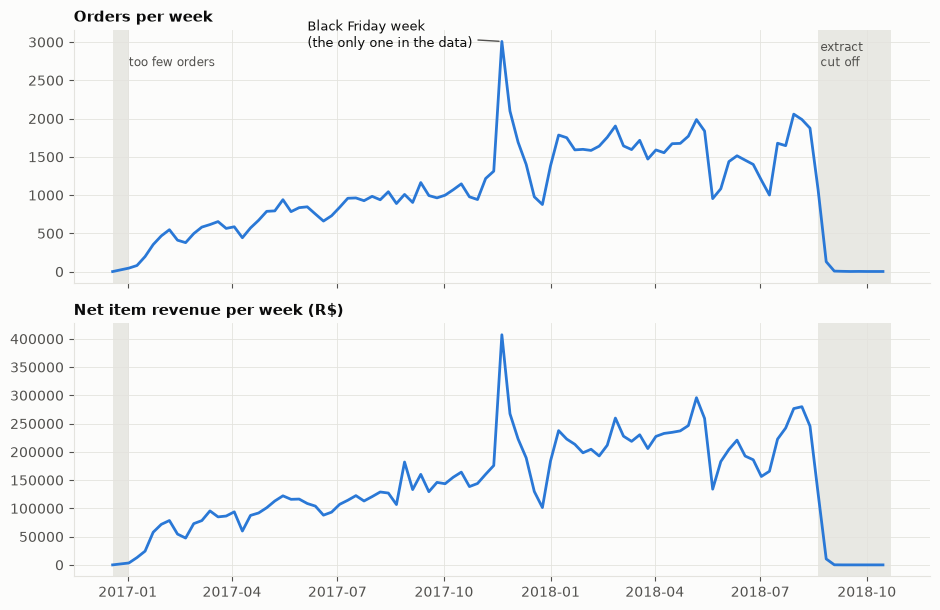

In [2]:
w = weekly.loc["2016-12-19":]
fig, (a, b) = plt.subplots(2, 1, figsize=(9.5, 6.2), sharex=True)
for ax, column, title in [(a, "orders", "Orders per week"), (b, "revenue", "Net item revenue per week (R$)")]:
    ax.plot(w.index, w[column], color=BLUE)
    ax.axvspan(w.index[0], fb.FIRST_WEEK, color=GRID, alpha=0.8, linewidth=0)
    ax.axvspan(fb.LAST_CLEAN_WEEK + pd.Timedelta(days=7), w.index[-1] + pd.Timedelta(days=7), color=GRID, alpha=0.8, linewidth=0)
    ax.set_title(title)
bf = fb.BLACK_FRIDAY_WEEKS[0]
a.annotate("Black Friday week\n(the only one in the data)", (bf, w.loc[bf, "orders"]), xytext=(-140, -4), textcoords="offset points", fontsize=9,
           arrowprops={"arrowstyle": "-", "color": INK_2})
a.text(w.index[1], a.get_ylim()[1] * 0.85, "too few orders", fontsize=8.5, color=INK_2)
a.text(fb.LAST_CLEAN_WEEK + pd.Timedelta(days=9), a.get_ylim()[1] * 0.85, "extract\ncut off", fontsize=8.5, color=INK_2)
plt.tight_layout()
plt.show()

Orders grew roughly tenfold through 2017 and then flattened around 6,000 to 7,000 a month in 2018. There is **one** Black Friday in the data (week of 2017-11-20), so whether it is a repeating seasonal peak cannot be tested.

## 2. How forecasts are tested

For every week from the 27th onward the methods are shown only the weeks *up to that point* and asked for the next week (1 week ahead) and for the week four ahead. Then the origin moves forward one week and it is repeated. This gives 59 one-week and 56 four-week forecasts per method. No method ever sees a week it is forecasting.

The six methods:

| method | idea |
|---|---|
| naive | repeat last week |
| moving average (8 weeks) | the average of the last eight weeks |
| simple exponential smoothing | a weighted average that favours recent weeks, weight fitted to the history |
| damped trend | a level plus a trend that fades out over time |
| AR(1) with trend | a small regression on last week and a time trend |
| combination | the average of the naive and 8-week-average forecasts |

In [3]:
main = weekly.loc[fb.FIRST_WEEK:fb.LAST_CLEAN_WEEK]
bt = {}
for target in ["orders", "revenue"]:
    for h in fb.HORIZONS:
        bt[(target, h)] = fb.backtest(main[target], h, fm.MODELS)
scores = {k: fb.score(v) for k, v in bt.items()}
print(f"{len(main)} weeks in the main series; one-week forecasts: {len(bt[('orders', 1)])}, four-week: {len(bt[('orders', 4)])}")

85 weeks in the main series; one-week forecasts: 59, four-week: 56


## 3. One week ahead: forecasts against what happened

The blue line is the actual number of orders. The grey line repeats last week, and the orange line is the combination forecast.

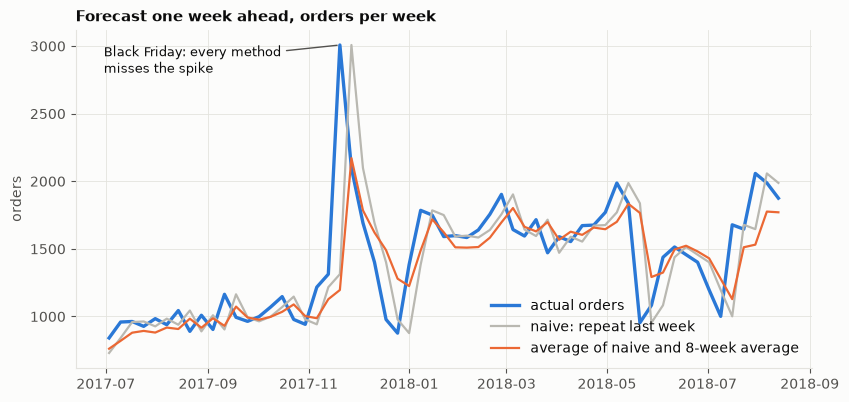

In [4]:
b1 = bt[("orders", 1)]
fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.plot(b1.index, b1["actual"], color=BLUE, label="actual orders", linewidth=2.4)
ax.plot(b1.index, b1["naive_last_week"], color=GREY, linewidth=1.6, label="naive: repeat last week")
ax.plot(b1.index, b1["combo_naive_ma8"], color=ORANGE, linewidth=1.6, label="average of naive and 8-week average")
bf = fb.BLACK_FRIDAY_WEEKS[0]
ax.annotate("Black Friday: every method\nmisses the spike", (bf, b1.loc[bf, "actual"]), xytext=(-170, -20), textcoords="offset points", fontsize=9,
            arrowprops={"arrowstyle": "-", "color": INK_2})
ax.set_title("Forecast one week ahead, orders per week")
ax.set_ylabel("orders")
ax.legend(frameon=False, loc="lower right")
plt.show()

The methods track the broad level well but are always a step behind the turning points, and none anticipates Black Friday. The orange line is a little closer to the blue one than the grey line is.

## 4. How big are the errors?

Mean absolute error (MAE), in orders per week, for one and four weeks ahead. The dashed line is the naive error; anything below it beats repeating last week.

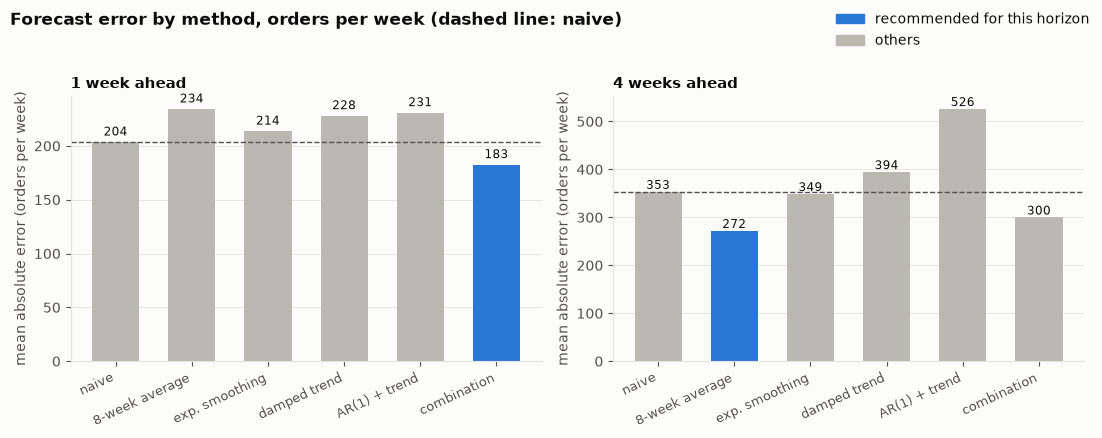

In [5]:
names = {"naive_last_week": "naive", "moving_average_8": "8-week average", "simple_exp_smoothing": "exp. smoothing",
         "damped_trend": "damped trend", "ar1_trend_26w": "AR(1) + trend", "combo_naive_ma8": "combination"}
order = list(names)
recommended = {1: "combo_naive_ma8", 4: "moving_average_8"}   # the method I recommend for each horizon

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharey=False)
for ax, h in zip(axes, fb.HORIZONS):
    mae = [scores[("orders", h)][m]["mae"] for m in order]
    colours = [BLUE if m == recommended[h] else GREY for m in order]
    ax.bar([names[m] for m in order], mae, color=colours, width=0.62)
    ax.axhline(mae[0], color=INK_2, linestyle="--", linewidth=1)
    for i, v in enumerate(mae):
        ax.text(i, v + 6, f"{v:.0f}", ha="center", fontsize=8.5)
    ax.set_title(f"{h} week{'s' if h > 1 else ''} ahead")
    ax.set_ylabel("mean absolute error (orders per week)")
    ax.grid(axis="x", visible=False)
    plt.setp(ax.get_xticklabels(), rotation=25, ha="right", fontsize=9)
fig.suptitle("Forecast error by method, orders per week (dashed line: naive)", x=0.01, ha="left", fontsize=12, fontweight="bold")
fig.legend(handles=[Patch(color=BLUE, label="recommended for this horizon"), Patch(color=GREY, label="others")], loc="upper right", frameon=False)
plt.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

- **One week ahead:** the combination has the smallest error (about 183 orders, 10% below naive). Smoothing and the regressions are no better than repeating last week.
- **Four weeks ahead:** the 8-week average is best (about 272, 23% below naive). The damped trend and the regression are *worse* than naive, and the regression's error is 49% higher.

## 5. When do the errors happen?

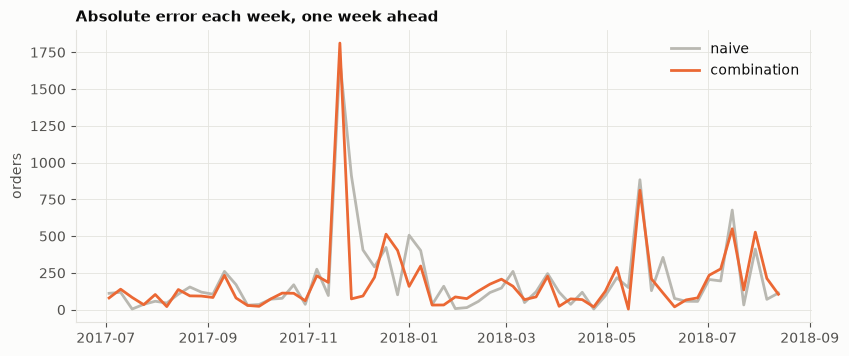

share of weeks where the combination beats naive: 51%


In [6]:
err = pd.DataFrame({
    "naive": (b1["actual"] - b1["naive_last_week"]).abs(),
    "combination": (b1["actual"] - b1["combo_naive_ma8"]).abs(),
})
fig, ax = plt.subplots(figsize=(9.5, 3.8))
ax.plot(err.index, err["naive"], color=GREY, label="naive")
ax.plot(err.index, err["combination"], color=ORANGE, label="combination")
ax.set_title("Absolute error each week, one week ahead")
ax.set_ylabel("orders")
ax.legend(frameon=False)
plt.show()
print("share of weeks where the combination beats naive:", f"{(err['combination'] < err['naive']).mean():.0%}")

The biggest errors cluster around Black Friday and the weeks after it, when the series jumps and then falls back. Outside that stretch the two methods are close. The combination beats naive in only about half of individual weeks; its lower *average* error comes from being less wrong when both are wrong, not from winning more often.

## 6. Can this backtest rank the methods? Not reliably.

The same methods were run on **revenue**, which moves together with orders. If the backtest could really tell good methods from bad ones, the ranking should be similar. Each dot is a method's error divided by the naive error (below 1 beats naive):

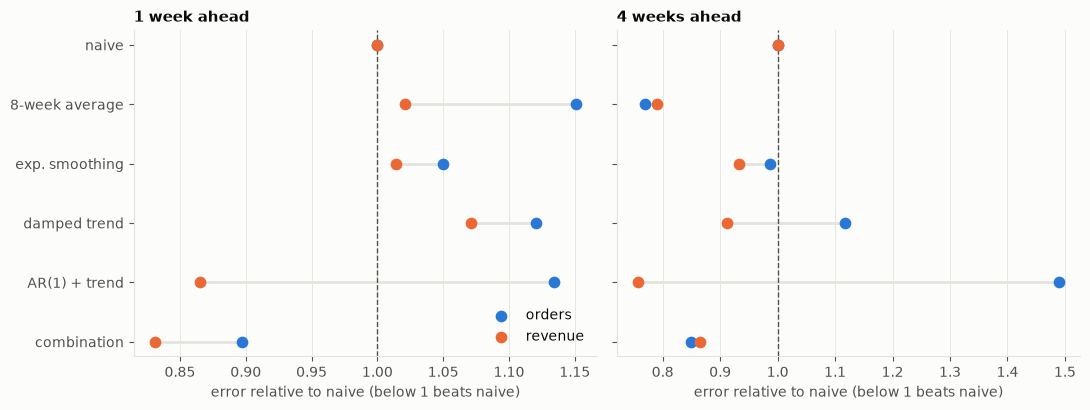

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, h in zip(axes, fb.HORIZONS):
    y = np.arange(len(order))[::-1]
    o = [scores[("orders", h)][m]["mae_vs_naive"] for m in order]
    r = [scores[("revenue", h)][m]["mae_vs_naive"] for m in order]
    for yi, a_, b_ in zip(y, o, r):
        ax.plot([a_, b_], [yi, yi], color=GRID, linewidth=2, zorder=1)
    ax.scatter(o, y, color=BLUE, s=55, zorder=3, label="orders")
    ax.scatter(r, y, color=ORANGE, s=55, zorder=3, label="revenue")
    ax.axvline(1.0, color=INK_2, linestyle="--", linewidth=1)
    ax.set_yticks(y)
    ax.set_yticklabels([names[m] for m in order])
    ax.set_title(f"{h} week{'s' if h > 1 else ''} ahead")
    ax.set_xlabel("error relative to naive (below 1 beats naive)")
    ax.grid(axis="y", visible=False)
axes[0].legend(frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

Look at the AR(1) + trend row. For orders it is among the worst methods (about 1.1 times the naive error one week ahead, and 1.5 times four weeks ahead); for revenue it is among the best (about 0.87 and 0.76). Two series that rise and fall together should not rank a method so differently. This means **85 weeks are too few to tell these methods apart**, and any ranking beyond "the simple averages are safe" should be treated with suspicion.

## Takeaways

- **One week ahead:** use the average of the naive forecast and the 8-week average. **Four weeks ahead:** use the 8-week average.
- **Do not trust the fancier methods on this little history.** Exponential smoothing, the damped trend and the regression do not reliably beat the simple ones, and their rankings flip between orders and revenue.
- **The combination was assembled after seeing that its two parts were the baseline winners**, so its advantage is optimistic. It beats naive in only half the weeks.
- **Every method under-forecasts on average** because orders grew through 2017, and **none anticipates Black Friday**; with one occurrence, seasonality cannot be learned.
- **More data would help more than a cleverer method**, in particular a second year, which would allow a seasonal forecast.

**Limits.** 85 weeks, one marketplace, data ending in 2018, no tuning. The week of 2018-08-20 looks truncated; including it changes the numbers only slightly (see the model card). Full tables are in [reports/forecast_models_metrics.json](../reports/forecast_models_metrics.json).